[epsilon = 0.1, alpha = 0.01]


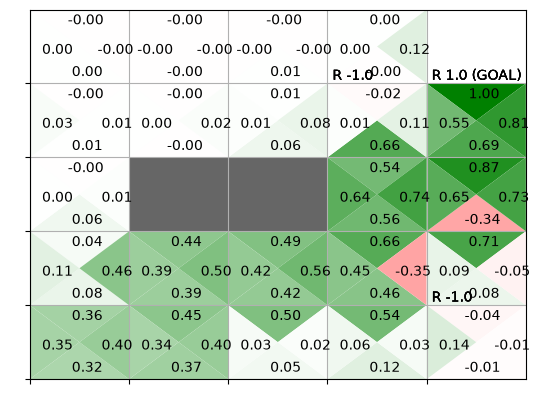

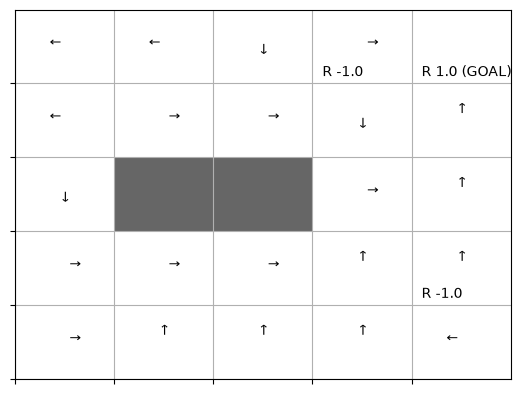

[epsilon = 0.1, alpha = 0.05]


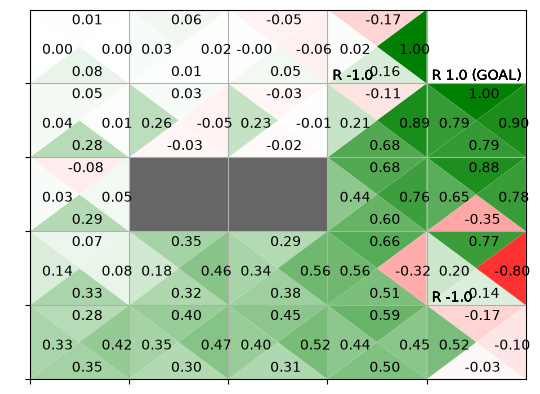

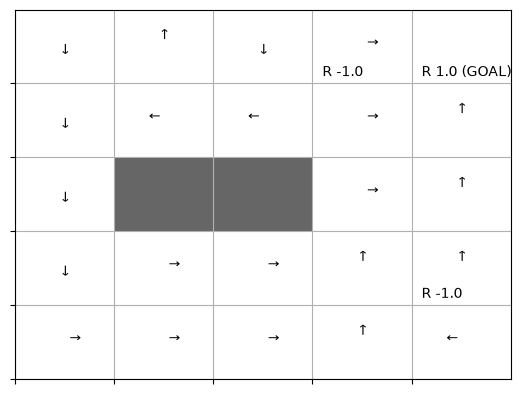

[epsilon = 0.1, alpha = 0.1]


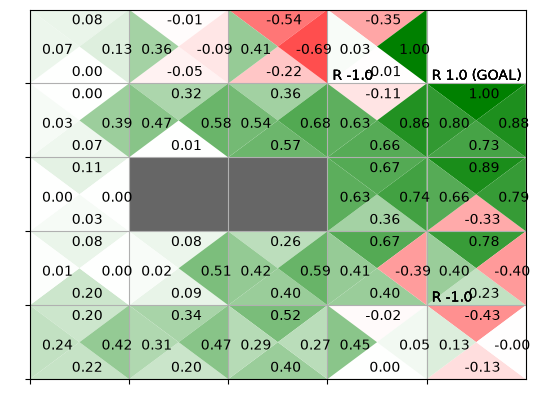

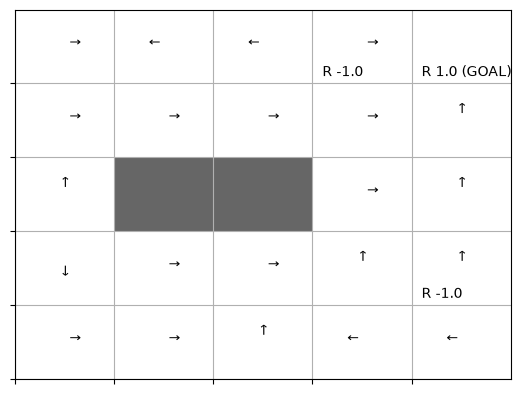

[epsilon = 0.1, alpha = 0.3]


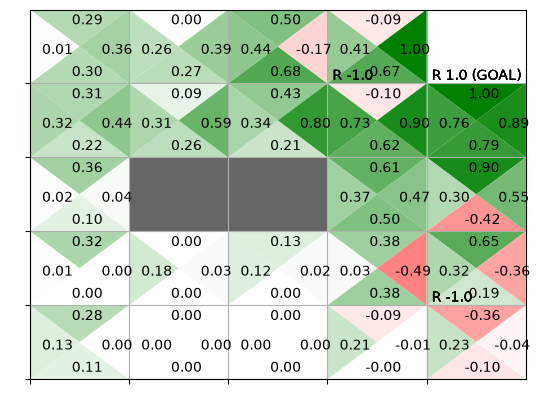

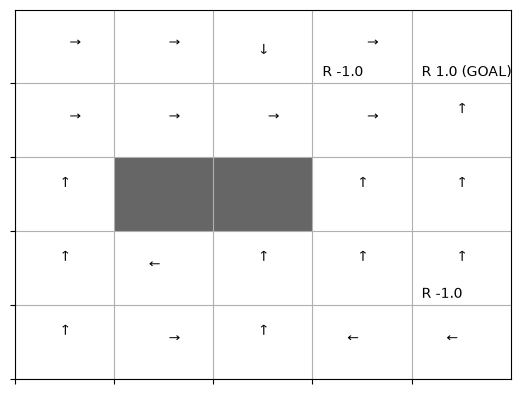

[epsilon = 0.1, alpha = 0.5]


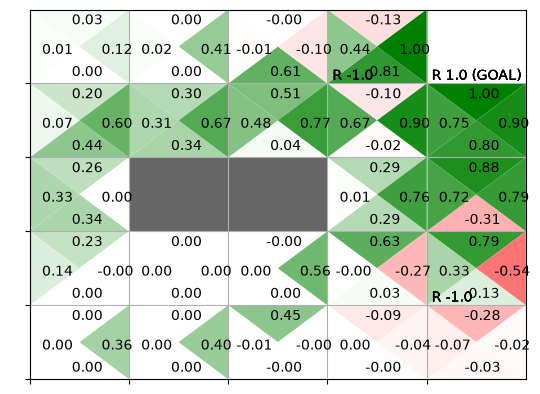

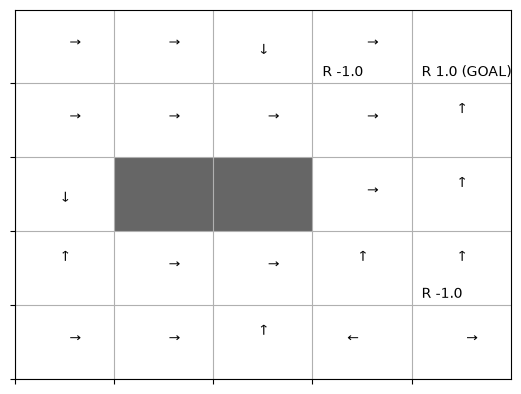

In [2]:
import os, sys;
sys.path.append(os.path.abspath('..')) # for importing the parent dirs
import numpy as np
from collections import defaultdict
from common.gridworld import GridWorld
from IPython.display import display
import ipywidgets as widgets
# from common.utils import greedy_probs


def greedy_probs(Q, state, epsilon=0, action_size=4):
    qs = [Q[(state, action)] for action in range(action_size)]
    max_action = np.argmax(qs)

    base_prob = epsilon / action_size
    action_probs = {action: base_prob for action in range(action_size)}  #{0: ε/4, 1: ε/4, 2: ε/4, 3: ε/4}
    action_probs[max_action] += (1 - epsilon)
    return action_probs


class McAgent:
    def __init__(self, epsilon=0.1, alpha=0.1):
        self.gamma = 0.9
        self.epsilon = epsilon  # (첫 번째 개선) ε-탐욕 정책의 ε
        self.alpha = alpha    # (두 번째 개선) Q 함수 갱신 시의 고정값 α
        self.action_size = 4

        random_actions = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}
        self.pi = defaultdict(lambda: random_actions)
        self.Q = defaultdict(lambda: 0)
        # self.cnts = defaultdict(lambda: 0)
        self.memory = []

    def get_action(self, state):
        action_probs = self.pi[state]
        actions = list(action_probs.keys())
        probs = list(action_probs.values())
        return np.random.choice(actions, p=probs)

    def add(self, state, action, reward):
        data = (state, action, reward)
        self.memory.append(data)

    def reset(self):
        self.memory.clear()

    def update(self):
        G = 0
        for data in reversed(self.memory):
            state, action, reward = data
            G = self.gamma * G + reward
            key = (state, action)
            # self.cnts[key] += 1
            # self.Q[key] += (G - self.Q[key]) / self.cnts[key]
            self.Q[key] += (G - self.Q[key]) * self.alpha
            self.pi[state] = greedy_probs(self.Q, state, self.epsilon)


env = GridWorld()
agent = McAgent()

alpha_values = [0.01, 0.05, 0.1, 0.3, 0.5]
episodes = 10000

for alpha in alpha_values:
    env = GridWorld()
    agent = McAgent(epsilon=0.1, alpha=alpha)

    for episode in range(episodes):
        state = env.reset()
        agent.reset()

        while True:
            action = agent.get_action(state)
            next_state, reward, done = env.step(action)

            agent.add(state, action, reward)

            if done:
                agent.update()
                break

            state = next_state

    print(f"[epsilon = 0.1, alpha = {alpha}]")
    env.render_q(agent.Q)